<a href="https://colab.research.google.com/github/Dedeepya0510/CSA4703---Deep-Learning/blob/main/Lab%20Experiment/Exp_19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: (1797, 64)
Components for 95% variance: 29
First 5 Scratch PCA: [0.14890594 0.13618771 0.11794594 0.08409979 0.05782415]
First 5 Scikit-learn PCA: [0.14890594 0.13618771 0.11794594 0.08409979 0.05782415]


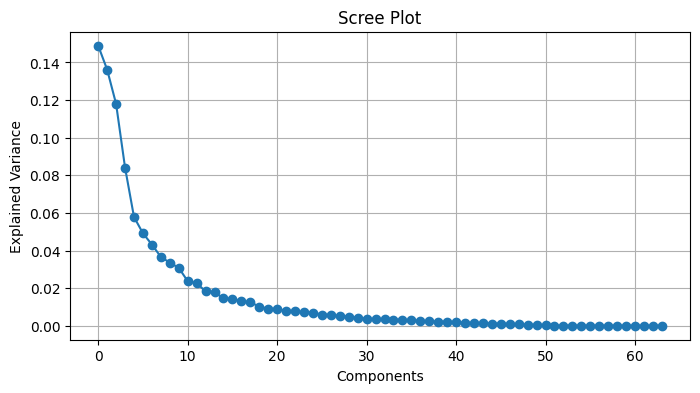

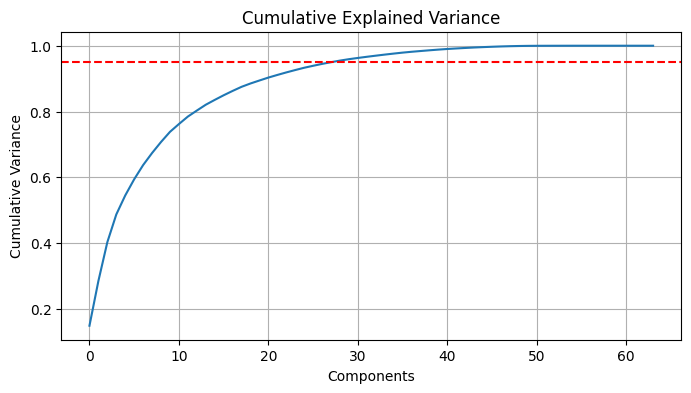

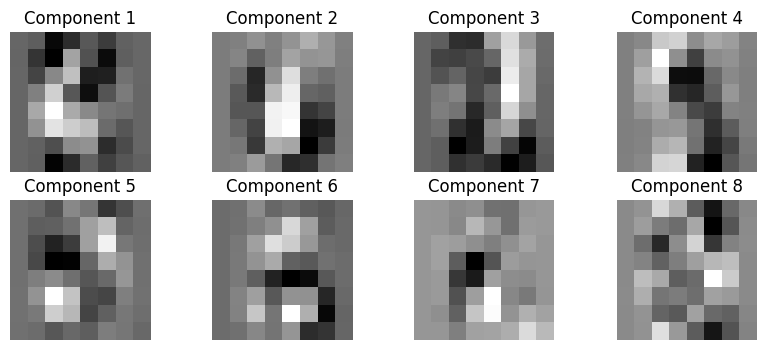

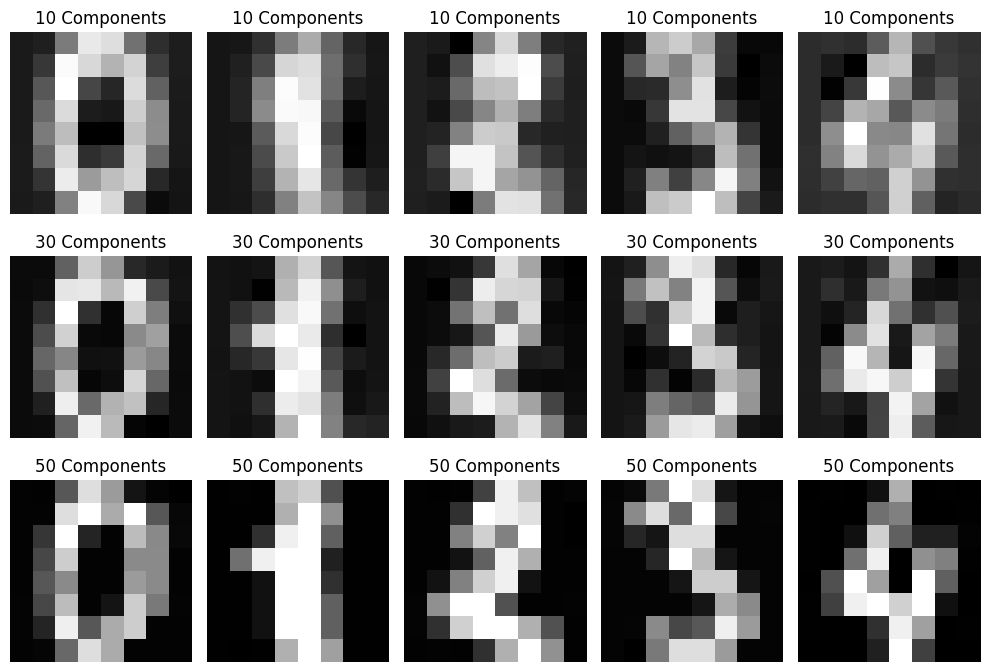

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA

# Load small handwritten digits dataset
digits = load_digits()
X = digits.data
images = digits.images

print("Dataset Shape:", X.shape)

# PCA from scratch using covariance matrix
mean = np.mean(X, axis=0)
X_centered = X - mean

cov = np.cov(X_centered, rowvar=False)

eigenvalues, eigenvectors = np.linalg.eigh(cov)

# Sort eigenvalues
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

# Explained variance
variance = eigenvalues / np.sum(eigenvalues)
cumulative = np.cumsum(variance)

n_components = np.argmax(cumulative >= 0.95) + 1

print("Components for 95% variance:", n_components)

# Compare with Scikit-learn
pca = PCA()
pca.fit(X)

print("First 5 Scratch PCA:", variance[:5])
print("First 5 Scikit-learn PCA:",
      pca.explained_variance_ratio_[:5])

# Scree plot
plt.figure(figsize=(8, 4))
plt.plot(variance, marker='o')
plt.title("Scree Plot")
plt.xlabel("Components")
plt.ylabel("Explained Variance")
plt.grid()
plt.show()

# Cumulative variance
plt.figure(figsize=(8, 4))
plt.plot(cumulative)
plt.axhline(0.95, color='red', linestyle='--')
plt.title("Cumulative Explained Variance")
plt.xlabel("Components")
plt.ylabel("Cumulative Variance")
plt.grid()
plt.show()

# Top eigenfaces/eigenvectors
plt.figure(figsize=(10, 4))
for i in range(8):
    plt.subplot(2, 4, i+1)
    plt.imshow(eigenvectors[:, i].reshape(8, 8), cmap='gray')
    plt.title(f"Component {i+1}")
    plt.axis('off')
plt.show()

# Reconstruct digits using different components
sample = X[:5]

plt.figure(figsize=(10, 7))

for row, k in enumerate([10, 30, 50]):
    model = PCA(n_components=k)
    model.fit(X)
    reconstructed = model.inverse_transform(model.transform(sample))

    for col in range(5):
        plt.subplot(3, 5, row*5+col+1)
        plt.imshow(reconstructed[col].reshape(8, 8), cmap='gray')
        plt.title(f"{k} Components")
        plt.axis('off')

plt.tight_layout()
plt.show()